## Email Campaign Experiment

**Questions:** 

Which campaign wins? 
Where in the funnel? 
How much extra revenue? 
Is it statistically impactful? 
Which customers should get which email?

In [1]:
# --- imports ---
import pandas as pd
from google.cloud import bigquery
from scipy.stats import ttest_ind_from_stats, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt

# general config
bq = bigquery.Client(project="abtes-510522")
s = bq.query(open("../sql/email_summary.sql").read()).to_dataframe().set_index("variant_group")
assert s.bad_rows.sum() == 0 and s.neg_spend.sum() == 0, "data check failed"
s

/Users/tranphuongvy/Projects/email-campaign/.venv/lib/python3.14/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)
/Users/tranphuongvy/Projects/email-campaign/.venv/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,users,visits,conversions,revenue,rev_per_user,rev_std,bad_rows,neg_spend
variant_group,,,,,,,,
mens e-mail,21307,3894,267,30311.69,1.422617,17.754205,0,0
no e-mail,21306,2262,122,13908.33,0.652789,11.588200,0,0
womens e-mail,21387,3238,189,23038.11,1.077202,15.116106,0,0


In [2]:
# funnel KPIs
k = pd.DataFrame({
    "users": s.users,
    "ctr": s.visits / s.users,
    "post_click_conv": s.conversions / s.visits,
    "conv_rate": s.conversions / s.users,
    "rev_per_user": s.rev_per_user,
    "rev_per_converter": s.revenue / s.conversions,
    "net_lift_$": (s.rev_per_user - s.rev_per_user["no e-mail"]) * s.users,
})
k

,users,ctr,post_click_conv,conv_rate,rev_per_user,rev_per_converter,net_lift_$
variant_group,,,,,,,
mens e-mail,21307,0.182757,0.068567,0.012531,1.422617,113.526929,16402.707211
no e-mail,21306,0.106167,0.053935,0.005726,0.652789,114.002705,0.0
womens e-mail,21387,0.1514,0.058369,0.008837,1.077202,121.894762,9076.904062


In [3]:
# Chi-square test to see if p < 0.05 (unbalanced split)
seg = bq.query(open("../sql/segments.sql").read()).to_dataframe()
num = ["users", "visits", "conversions", "revenue", "rev_per_user", "rev_std"]
seg[num] = seg[num].astype(float) # BigQuery returns nullable Int64, which scipy rejects

balance_p = {dim: chi2_contingency(g.pivot(index="segment", columns="variant_group", values="users").fillna(0))[1]
             for dim, g in seg.groupby("dimension")}
pd.Series(balance_p, name="chi2_p").round(3)

/Users/tranphuongvy/Projects/email-campaign/.venv/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


channel          0.458
customer_type    0.934
geo_zone         0.579
past_purchase    0.742
recency          0.868
spend_tier       0.358
Name: chi2_p, dtype: float64

Segments are perfectly balanced and randomized, campaign results are believable.

In [4]:
# pairwise tests, Holm-adjusted per metric family
def test(a, b):
    ra, rb = s.loc[a], s.loc[b]
    return {
        "pair": f"{a} vs {b}",
        "ctr_p": proportions_ztest([ra.visits, rb.visits], [ra.users, rb.users])[1],
        "conv_p": proportions_ztest([ra.conversions, rb.conversions], [ra.users, rb.users])[1],
        "post_click_p": proportions_ztest([ra.conversions, rb.conversions], [ra.visits, rb.visits])[1],
        "revenue_p": ttest_ind_from_stats(ra.rev_per_user, ra.rev_std, ra.users,
                                          rb.rev_per_user, rb.rev_std, rb.users, equal_var=False).pvalue,
    }

pairs = [("mens e-mail", "no e-mail"), ("womens e-mail", "no e-mail"), ("mens e-mail", "womens e-mail")]
p = pd.DataFrame([test(a, b) for a, b in pairs]).set_index("pair")
for c in p:
    p[c] = multipletests(p[c], method="holm")[1]
p.apply(lambda c: c.map("{:.2e}".format))

,ctr_p,conv_p,post_click_p,revenue_p
pair,,,,
mens e-mail vs no e-mail,1.71e-111,4.57e-13,6.87e-02,3.49e-07
womens e-mail vs no e-mail,6.36e-44,3.14e-04,4.84e-01,2.26e-03
mens e-mail vs womens e-mail,3.80e-18,3.14e-04,1.59e-01,3.05e-02


In [5]:
# revenue boost with uncertainty (95% confidence interval)
def lift_ci(m1, sd1, n1, m0, sd0, n0):
    """Difference in mean revenue per user with a 95% CI (normal approx; n is ~21k per group)."""
    d = m1 - m0
    se = (sd1**2 / n1 + sd0**2 / n0) ** 0.5
    return d, d - 1.96 * se, d + 1.96 * se

c = s.loc["no e-mail"]
rows = {}
for e in ["mens e-mail", "womens e-mail"]:
    r = s.loc[e]
    d, lo, hi = lift_ci(r.rev_per_user, r.rev_std, r.users, c.rev_per_user, c.rev_std, c.users)
    rows[e] = {"lift_per_user": d, "ci_low": lo, "ci_high": hi,
               "incremental_$": d * r.users, "incr_low_$": lo * r.users, "incr_high_$": hi * r.users}
pd.DataFrame(rows).T.round(2)

,lift_per_user,ci_low,ci_high,incremental_$,incr_low_$,incr_high_$
mens e-mail,0.77,0.49,1.05,16402.71,10336.96,22468.45
womens e-mail,0.42,0.17,0.68,9076.90,3613.54,14540.26


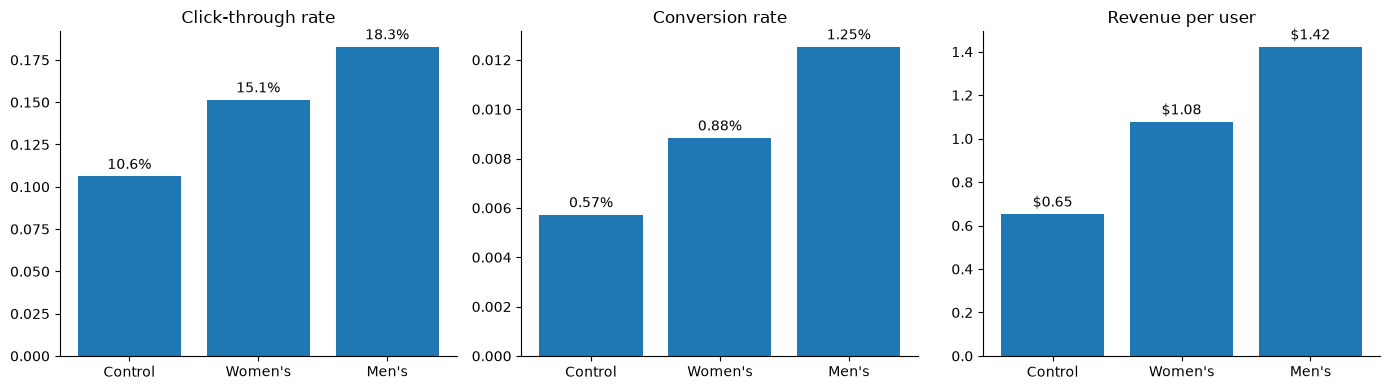

In [6]:
# charts
names = {"no e-mail": "Control", "womens e-mail": "Women's", "mens e-mail": "Men's"}
order = list(names)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, title, fmt in zip(ax, ["ctr", "conv_rate", "rev_per_user"],
                              ["Click-through rate", "Conversion rate", "Revenue per user"],
                              ["{:.1%}", "{:.2%}", "${:.2f}"]):
    v = k.loc[order, col]
    bars = a.bar([names[i] for i in order], v)
    a.bar_label(bars, labels=[fmt.format(x) for x in v], padding=3)
    a.set_title(title)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

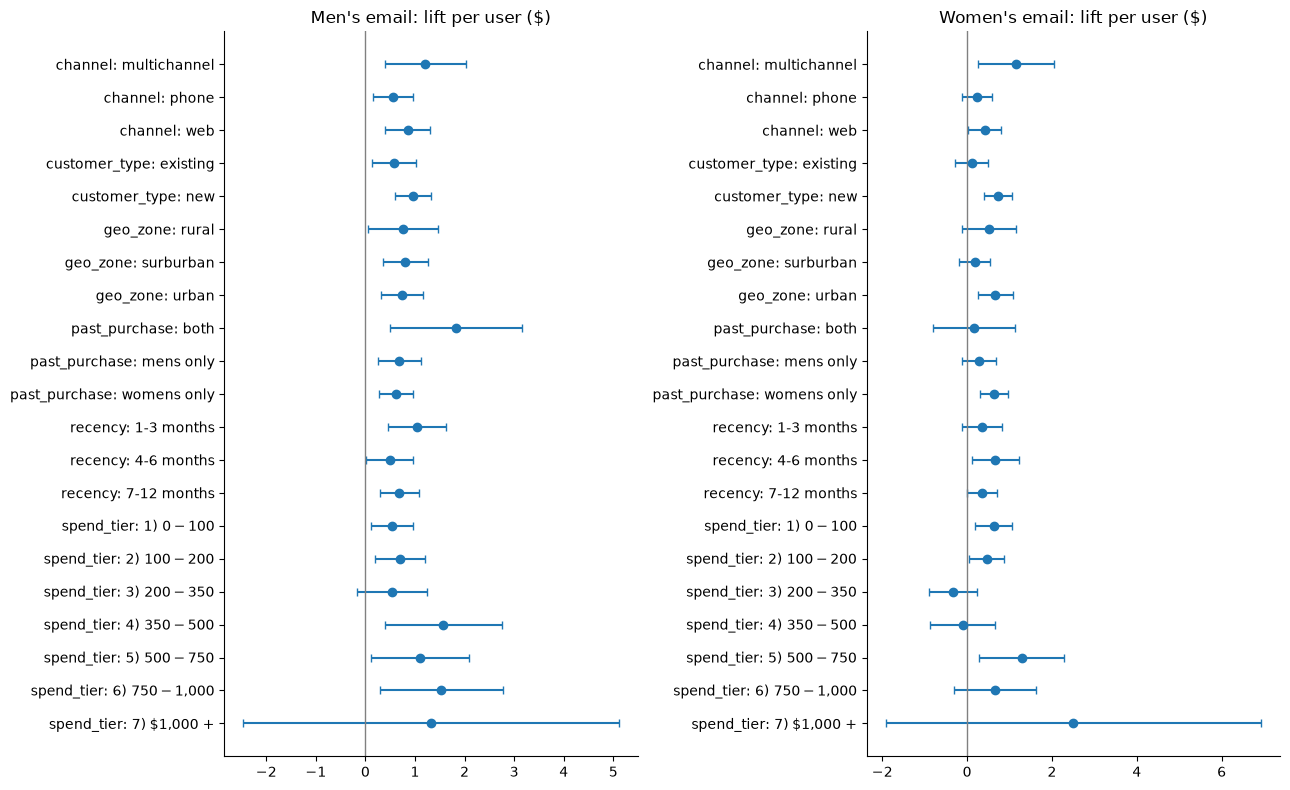

In [7]:
# revenue boost per user by segment
w = seg.pivot_table(index=["dimension", "segment"], columns="variant_group",
                    values=["users", "rev_per_user", "rev_std"])

res = {}
for e in ["mens e-mail", "womens e-mail"]:
    d, lo, hi = lift_ci(w["rev_per_user"][e], w["rev_std"][e], w["users"][e],
                        w["rev_per_user"]["no e-mail"], w["rev_std"]["no e-mail"], w["users"]["no e-mail"])
    res[e] = pd.DataFrame({"lift": d, "lo": lo, "hi": hi}).dropna()

# plot
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
for ax, (e, r) in zip(axes, res.items()):
    ax.errorbar(r.lift, range(len(r)), xerr=[r.lift - r.lo, r.hi - r.lift], fmt="o", capsize=3)
    ax.axvline(0, color="grey", lw=1)
    ax.set_yticks(range(len(r)), [f"{a}: {b}" for a, b in r.index])
    ax.invert_yaxis()
    ax.set_title(f"{names[e]} email: lift per user ($)")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [8]:
# most profitable email for each segment
COST = 0.10 # assumed $ cost per email send
DIM = "past_purchase"

u = w["users"].xs(DIM)
t = pd.DataFrame({
    "share": u.sum(axis=1) / u.sum().sum(),
    "mens": res["mens e-mail"].lift.xs(DIM),
    "womens": res["womens e-mail"].lift.xs(DIM),
})
t["best"] = t[["mens", "womens"]].idxmax(axis=1)
t["best_net"] = t[["mens", "womens"]].max(axis=1) - COST

display(t.round(3))

profit_per_1000 = pd.Series({
    "email everyone: men's": 1000 * (t.share * (t.mens - COST)).sum(),
    "email everyone: women's": 1000 * (t.share * (t.womens - COST)).sum(),
    "targeted: best email per segment, skip if lift < cost": 1000 * (t.share * t.best_net.clip(lower=0)).sum(),
}).round(0)
profit_per_1000.rename("incremental revenue minus email cost, per 1,000 customers")

,share,mens,womens,best,best_net
segment,,,,,
both,0.101,1.825,0.162,mens,1.725
mens only,0.450,0.683,0.278,mens,0.583
womens only,0.449,0.616,0.632,womens,0.532


email everyone: men's                                    668.0
email everyone: women's                                  325.0
targeted: best email per segment, skip if lift < cost    675.0
Name: incremental revenue minus email cost, per 1,000 customers, dtype: float64

## Key findings
- **Men's email wins on CTR, conversion rate and revenue per user** with CTR 18.3%, conversion 1.25%, revenue per user $1.42.

- Estimated incremental revenue vs control: **~$16.4k men's, ~$9.1k women's** (**~$25.5k** combined)

- Via Holm's correction, we see that the revenue boost came from getting more people to click, not because the emails magically convinced visitors to spend more cash per order.

- All major findings are statistically real and verified, meaning the results are a true reflection of customer interest.